# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [121]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [122]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def _validate_board(board):
    """Validate the one-queen-per-column representation and return a list."""
    values = list(board)
    if not values:
        raise ValueError("A board must contain at least one queen.")
    if any(not isinstance(row, (int, np.integer)) for row in values):
        raise TypeError("Each board entry must be an integer row index.")
    n = len(values)
    if any(row < 0 or row >= n for row in values):
        raise ValueError("Each row index must be between 0 and n - 1.")
    return [int(row) for row in values]


def random_board(n, rng=None):
    """Create a board with exactly one randomly placed queen per column."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer.")
    if rng is None:
        return np.random.randint(0, n, size=n)
    return rng.integers(0, n, size=n)


def comb2(count):
    """Return the number of unordered pairs in a group."""
    return count * (count - 1) // 2


def h(board):
    """Count attacking queen pairs: same row or either diagonal."""
    board = _validate_board(board)
    n = len(board)
    row_counts = [0] * n
    descending_counts = [0] * (2 * n - 1)
    ascending_counts = [0] * (2 * n - 1)
    for column, row in enumerate(board):
        row_counts[row] += 1
        descending_counts[column - row + n - 1] += 1
        ascending_counts[column + row] += 1
    return sum(comb2(count) for counts in
               (row_counts, descending_counts, ascending_counts)
               for count in counts)


def conflicts(board):
    """Backward-compatible name for the n-Queens objective function h."""
    return h(board)


def show_board(board, cols=('white', 'gray'), fontsize=48):
    """Display a board and its objective value; return the figure and axes."""
    board = _validate_board(board)
    n = len(board)
    display = np.fromfunction(lambda row, col: (row + col) % 2, (n, n))
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap=cmap,
              norm=colors.BoundaryNorm(range(len(cols) + 1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    for column, row in enumerate(board):
        ax.text(column, row, "\u265b", fontsize=fontsize,
                horizontalalignment='center', verticalalignment='center')
    print(f"Board with h(board) = {h(board)} conflicts.")
    plt.show()
    return fig, ax


## Create a board

n = 4; board = [3, 3, 2, 1]; h(board) = 4
Board with h(board) = 4 conflicts.


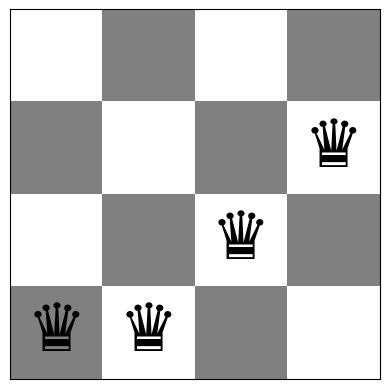

(<Figure size 640x480 with 1 Axes>, <Axes: >)

In [123]:
board = random_board(4)
print(f"n = {len(board)}; board = {board.tolist()}; h(board) = {h(board)}")
show_board(board)

### Bài 5 — Biểu diễn bàn cờ và hàm mục tiêu

Bàn cờ được biểu diễn bằng vector `board` độ dài `n`: `board[i]` là hàng (đánh số từ 0) của quân hậu ở cột `i`. Vì mỗi phần tử tương ứng đúng một cột nên biểu diễn luôn có chính xác một quân hậu mỗi cột; không cần kiểm tra xung đột cột.

Hàm mục tiêu cần tối thiểu hóa là

$$h(board)=\sum_r {R_r \choose 2}+\sum_d {D_d \choose 2}+\sum_a {A_a \choose 2},$$

trong đó `R`, `D`, `A` lần lượt là số quân hậu trên mỗi hàng và hai hướng đường chéo. Mỗi cặp tấn công chỉ được đếm một lần. Do đó `h(board) = 0` khi và chỉ khi không có cặp quân hậu nào cùng hàng hoặc cùng đường chéo.

Bàn cờ mẫu `[1, 3, 0, 2]` là nghiệm cho `n = 4`. Cell kế tiếp kiểm tra tính tương đương trên toàn bộ `4^4` trạng thái của bàn cờ 4x4 và hiển thị một bàn cờ 8x8.

Bàn cờ mẫu: [1, 3, 0, 2]; h(board) = 0
Board with h(board) = 0 conflicts.


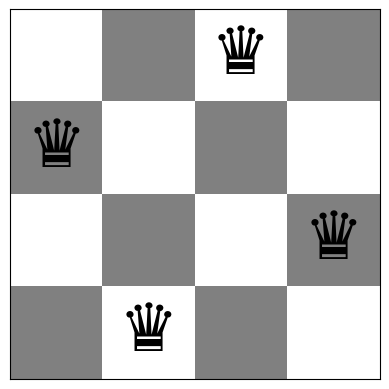

(<Figure size 640x480 with 1 Axes>, <Axes: >)

In [124]:
board = [1, 3, 0, 2]
print(f"Bàn cờ mẫu: {board}; h(board) = {h(board)}")
assert h(board) == 0
show_board(board)

Đã kiểm tra 256 bàn cờ 4x4: h(board) = 0 khi và chỉ khi không có cặp tấn công.
Ví dụ n = 8; board = [2, 0, 1, 0, 6, 1, 1, 3]; h(board) = 9
Board with h(board) = 9 conflicts.


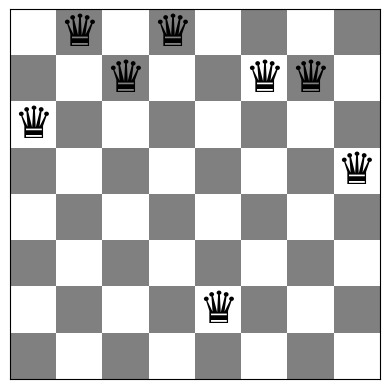

(<Figure size 640x480 with 1 Axes>, <Axes: >)

In [125]:
# Verify h(board) = 0 exactly when no pair of queens attacks on every 4x4 state.
def has_attacking_pair(board):
    return any(
        board[i] == board[j] or abs(board[i] - board[j]) == j - i
        for i in range(len(board))
        for j in range(i + 1, len(board))
    )

checked = 0
for encoded in range(4 ** 4):
    value = encoded
    candidate = []
    for _ in range(4):
        candidate.append(value % 4)
        value //= 4
    assert (h(candidate) == 0) == (not has_attacking_pair(candidate))
    checked += 1
print(f"Đã kiểm tra {checked} bàn cờ 4x4: h(board) = 0 khi và chỉ khi không có cặp tấn công.")

board8 = random_board(8, rng=np.random.default_rng(805))
print(f"Ví dụ n = 8; board = {board8.tolist()}; h(board) = {h(board8)}")
show_board(board8, fontsize=32)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 


`steps` đếm số nước đi được chấp nhận; `evaluations` đếm mọi lần tính `h`, gồm trạng thái ban đầu và các láng giềng được xét. Khi không còn nước cải thiện, trạng thái là `local_optimum` (cực tiểu theo nước đi một quân hậu); nếu có láng giềng cùng h nhưng không có nước tốt hơn thì ghi `plateau`.


In [126]:
from dataclasses import dataclass
from math import ceil, log

@dataclass
class NQueensResult:
    algorithm: str
    board: list
    conflicts: int
    steps: int
    evaluations: int
    status: str
    history: list

def _random_index(high, rng=None):
    return int(np.random.randint(high)) if rng is None else int(rng.integers(high))

def _choose(values, rng=None):
    return values[_random_index(len(values), rng)]

def _neighbor_boards(board):
    """Yield every legal one-queen move, excluding the current row."""
    n = len(board)
    for column, old_row in enumerate(board):
        for new_row in range(n):
            if new_row != old_row:
                neighbor = board.copy()
                neighbor[column] = new_row
                yield neighbor

def _random_neighbor(board, rng=None):
    """Sample uniformly from the n * (n - 1) legal one-queen moves."""
    n = len(board)
    if n < 2:
        return None
    move = _random_index(n * (n - 1), rng)
    column, offset = divmod(move, n - 1)
    old_row = board[column]
    new_row = offset if offset < old_row else offset + 1
    neighbor = board.copy()
    neighbor[column] = new_row
    return neighbor

def _finish(name, board, value, evaluations, steps, status, history):
    return NQueensResult(name, board, value, steps, evaluations, status, history)

def steepest_ascent_hill_climbing(start, rng=None, max_steps=100_000):
    """Evaluate the full neighborhood and take a best strict improvement."""
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")
    board = _validate_board(start)
    current = h(board)
    evaluations, steps, history = 1, 0, [current]
    if current == 0:
        return _finish("Steepest-ascent", board, current, evaluations, steps, "solution", history)

    for _ in range(max_steps):
        best_value = current
        best_neighbors = []
        has_plateau_neighbor = False
        for neighbor in _neighbor_boards(board):
            value = h(neighbor)
            evaluations += 1
            if value < best_value:
                best_value, best_neighbors = value, [neighbor]
            elif value == best_value and value < current:
                best_neighbors.append(neighbor)
            elif value == current:
                has_plateau_neighbor = True
        if not best_neighbors:
            status = "plateau" if has_plateau_neighbor else "local_optimum"
            return _finish("Steepest-ascent", board, current, evaluations, steps, status, history)
        board = _choose(best_neighbors, rng)
        current = best_value
        steps += 1
        history.append(current)
        if current == 0:
            return _finish("Steepest-ascent", board, current, evaluations, steps, "solution", history)
    return _finish("Steepest-ascent", board, current, evaluations, steps, "step_limit", history)

def inefficient_stochastic_hill_climbing(start, rng=None, max_steps=100_000):
    """Evaluate all neighbors, then randomly choose among all improvements."""
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")
    board = _validate_board(start)
    current = h(board)
    evaluations, steps, history = 1, 0, [current]
    if current == 0:
        return _finish("Inefficient stochastic", board, current, evaluations, steps, "solution", history)

    for _ in range(max_steps):
        improving = []
        has_plateau_neighbor = False
        for neighbor in _neighbor_boards(board):
            value = h(neighbor)
            evaluations += 1
            if value < current:
                improving.append((neighbor, value))
            elif value == current:
                has_plateau_neighbor = True
        if not improving:
            status = "plateau" if has_plateau_neighbor else "local_optimum"
            return _finish("Inefficient stochastic", board, current, evaluations, steps, status, history)
        board, current = _choose(improving, rng)
        steps += 1
        history.append(current)
        if current == 0:
            return _finish("Inefficient stochastic", board, current, evaluations, steps, "solution", history)
    return _finish("Inefficient stochastic", board, current, evaluations, steps, "step_limit", history)

def efficient_stochastic_hill_climbing(
    start, rng=None, max_steps=100_000, no_improvement_limit=None
):
    """Sample one random neighbor at a time and stop after a finite failure budget."""
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")
    board = _validate_board(start)
    current = h(board)
    evaluations, steps, history = 1, 0, [current]
    if current == 0:
        return _finish("Efficient stochastic", board, current, evaluations, steps, "solution", history)

    neighborhood_size = len(board) * (len(board) - 1)
    if neighborhood_size == 0:
        return _finish("Efficient stochastic", board, current, evaluations, steps, "local_optimum", history)
    if no_improvement_limit is None:
        no_improvement_limit = ceil(neighborhood_size * log(neighborhood_size / 0.01))
    if no_improvement_limit < 1:
        raise ValueError("no_improvement_limit must be positive.")

    failures = attempts = 0
    while attempts < max_steps and failures < no_improvement_limit:
        neighbor = _random_neighbor(board, rng)
        value = h(neighbor)
        evaluations += 1
        attempts += 1
        if value < current:
            board, current = neighbor, value
            steps += 1
            history.append(current)
            failures = 0
            if current == 0:
                return _finish("Efficient stochastic", board, current, evaluations, steps, "solution", history)
        else:
            failures += 1
    status = "stalled" if failures >= no_improvement_limit else "step_limit"
    return _finish("Efficient stochastic", board, current, evaluations, steps, status, history)


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.


Mỗi vòng đánh giá toàn bộ láng giềng rồi chọn ngẫu nhiên trong các nước cải thiện. Kết quả chạy mẫu cùng số bước và số đánh giá được in bên dưới.


In [127]:
initial_board = random_board(8, rng=np.random.default_rng(806))
print(f"Bàn cờ bắt đầu (n=8): {initial_board.tolist()}  |  h = {h(initial_board)}")

algorithms = (
    steepest_ascent_hill_climbing,
    inefficient_stochastic_hill_climbing,
    efficient_stochastic_hill_climbing,
)
single_run_results = []
for index, algorithm in enumerate(algorithms):
    result = algorithm(initial_board, rng=np.random.default_rng(900 + index))
    single_run_results.append(result)
    print(
        f"{result.algorithm:22} | h cuối ={result.conflicts:2} | "
        f"bước ={result.steps:3} | đánh giá ={result.evaluations:6} | "
        f"trạng thái ={result.status}"
    )

Bàn cờ bắt đầu (n=8): [3, 3, 6, 1, 2, 4, 6, 3]  |  h = 6
Steepest-ascent        | h cuối = 2 | bước =  3 | đánh giá =   225 | trạng thái =plateau
Inefficient stochastic | h cuối = 2 | bước =  3 | đánh giá =   225 | trạng thái =plateau
Efficient stochastic   | h cuối = 3 | bước =  3 | đánh giá =   495 | trạng thái =stalled


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.


Để tránh lặp vô hạn, dừng sau `ceil(M * ln(M / 0.01))` lần thử liên tiếp không cải thiện, với `M = n(n-1)` là số nước đi hợp lệ; có thể ghi đè `no_improvement_limit`. Trạng thái `stalled` là dừng theo ngân sách lấy mẫu, không chứng minh cực tiểu cục bộ vì chưa duyệt hết láng giềng.


In [128]:
efficient_result = efficient_stochastic_hill_climbing(
    initial_board,
    rng=np.random.default_rng(903),
    no_improvement_limit=500,
)
print(f"Bàn cờ cuối: {efficient_result.board}")
print(f"h cuối = {efficient_result.conflicts}; bước cải thiện = {efficient_result.steps}; "
      f"đánh giá = {efficient_result.evaluations}; trạng thái = {efficient_result.status}")
print(f"Lịch sử h sau mỗi bước cải thiện: {efficient_result.history}")
print("'stalled' nghĩa là hết ngân sách thử liên tiếp không cải thiện;\n"
      "vì chưa duyệt hết láng giềng nên chưa chứng minh được cực tiểu cục bộ.")

Bàn cờ cuối: [5, 0, 6, 1, 2, 4, 7, 3]
h cuối = 2; bước cải thiện = 3; đánh giá = 549; trạng thái = stalled
Lịch sử h sau mỗi bước cải thiện: [6, 4, 3, 2]
'stalled' nghĩa là hết ngân sách thử liên tiếp không cải thiện;
vì chưa duyệt hết láng giềng nên chưa chứng minh được cực tiểu cục bộ.


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.


`max_restarts=100` cho phép tối đa 100 lần khởi động lại sau lần chạy đầu tiên (tối đa 101 bàn cờ). Thực nghiệm lặp 20 chiến dịch độc lập cho mỗi cỡ bàn và thuật toán; báo cáo số chiến dịch tìm được nghiệm cùng chi phí trung bình.


In [129]:
from dataclasses import dataclass

@dataclass
class RestartSummary:
    algorithm: str
    n: int
    success: bool
    best_board: list
    conflicts: int
    attempts: int
    restarts: int
    steps: int
    evaluations: int
    status: str

def random_restart(algorithm, n, max_restarts=100, rng=None, **algorithm_options):
    """Try random starts until solved or max_restarts fresh restarts are used."""
    if not isinstance(max_restarts, int) or max_restarts < 0:
        raise ValueError("max_restarts must be a non-negative integer.")
    if n < 1:
        raise ValueError("n must be positive.")

    best_result = None
    total_steps = total_evaluations = attempts = 0
    for _ in range(max_restarts + 1):
        start = random_board(n, rng)
        result = algorithm(start, rng=rng, **algorithm_options)
        attempts += 1
        total_steps += result.steps
        total_evaluations += result.evaluations
        if best_result is None or result.conflicts < best_result.conflicts:
            best_result = result
        if result.conflicts == 0:
            break

    return RestartSummary(
        algorithm=best_result.algorithm,
        n=n,
        success=best_result.conflicts == 0,
        best_board=best_result.board,
        conflicts=best_result.conflicts,
        attempts=attempts,
        restarts=attempts - 1,
        steps=total_steps,
        evaluations=total_evaluations,
        status=best_result.status,
    )

# Twenty independent campaigns per setting; each allows at most 100 restarts.
# Each campaign ends when its first zero-conflict board is found.
trials = 20
restart_rows = []
for n in (4, 8):
    for algorithm_index, algorithm in enumerate(algorithms):
        summaries = [
            random_restart(
                algorithm,
                n,
                max_restarts=100,
                rng=np.random.default_rng(10_000 * n + 100 * algorithm_index + trial),
            )
            for trial in range(trials)
        ]
        successes = sum(summary.success for summary in summaries)
        mean_restarts = sum(summary.restarts for summary in summaries) / trials
        mean_evaluations = sum(summary.evaluations for summary in summaries) / trials
        mean_steps = sum(summary.steps for summary in summaries) / trials
        restart_rows.append((n, summaries[0].algorithm, successes, trials,
                             mean_restarts, mean_steps, mean_evaluations))

print(" n | Algorithm             | Solved campaigns | Mean restarts | Mean steps | Mean h evaluations")
for n, name, successes, total, restarts, steps, evaluations in restart_rows:
    print(f"{n:2} | {name:21} | {successes:2}/{total:<13} | "
          f"{restarts:13.2f} | {steps:10.2f} | {evaluations:19.2f}")

 n | Algorithm             | Solved campaigns | Mean restarts | Mean steps | Mean h evaluations
 4 | Steepest-ascent       | 20/20            |          1.30 |       3.50 |               59.90
 4 | Inefficient stochastic | 20/20            |          1.55 |       4.95 |               80.55
 4 | Efficient stochastic  | 20/20            |          1.35 |       4.80 |              140.55
 8 | Steepest-ascent       | 20/20            |          4.40 |      17.60 |             1237.40
 8 | Inefficient stochastic | 20/20            |          4.20 |      25.45 |             1665.60
 8 | Efficient stochastic  | 20/20            |          6.50 |      36.35 |             3674.05


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [130]:
# Code and description go here

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [131]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [132]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [133]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [134]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [135]:
# Code and description go here